<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/trees-forests-neural-networks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# A common workflow for classification and regression

We compare a decision tree, random forest and neural network on Iris classification and numerical diabetes progression. Both applications use scikit-learn. The same fitting, validation and test observations are used within each task. The dedicated MNIST and galaxy notebooks repeat the workflow on images.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

## Classification

Four measured flower lengths predict the species. `predict_proba` returns class probabilities. Balanced accuracy evaluates the hard decisions.

In [2]:
data = load_iris()
X, y = data.data, data.target
feature_names = list(data.feature_names)
classification = True

pool, test = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED,
                             stratify=y if classification else None)
fit, val = train_test_split(pool, test_size=.25, random_state=SEED,
                           stratify=y[pool] if classification else None)
print("Fitting / validation / test", len(fit), len(val), len(test))


models = {
    "Tree": DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=SEED),
    "Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=SEED, n_jobs=2),
    "Network": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,),
                  activation="tanh", solver="lbfgs", alpha=1., max_iter=5000, random_state=SEED))}
for model in models.values():
    model.fit(X[fit], y[fit])

Fitting / validation / test 90 30 30


In [3]:
validation_rows = []
for name, model in models.items():
    pred = model.predict(X[val])
    value = (balanced_accuracy_score(y[val], pred) if classification
             else root_mean_squared_error(y[val], pred))
    validation_rows.append({"model": name, "validation score": value})
display(pd.DataFrame(validation_rows))

,model,validation score
0,Tree,0.966667
1,Forest,0.966667
2,Network,0.933333


The settings are declared before test inspection. Compare with the majority-class baseline and inspect which species are confused.

In [4]:
baseline = DummyClassifier(strategy="most_frequent") if classification else DummyRegressor(strategy="mean")
baseline.fit(X[fit], y[fit])
test_rows = []
for name, model in {"Baseline": baseline, **models}.items():
    pred = model.predict(X[test])
    value = (balanced_accuracy_score(y[test], pred) if classification
             else root_mean_squared_error(y[test], pred))
    test_rows.append({"model": name, "test score": float(value)})
test_scores = pd.DataFrame(test_rows)
display(test_scores)

,model,test score
0,Baseline,0.333333
1,Tree,0.900000
2,Forest,0.933333
3,Network,0.966667


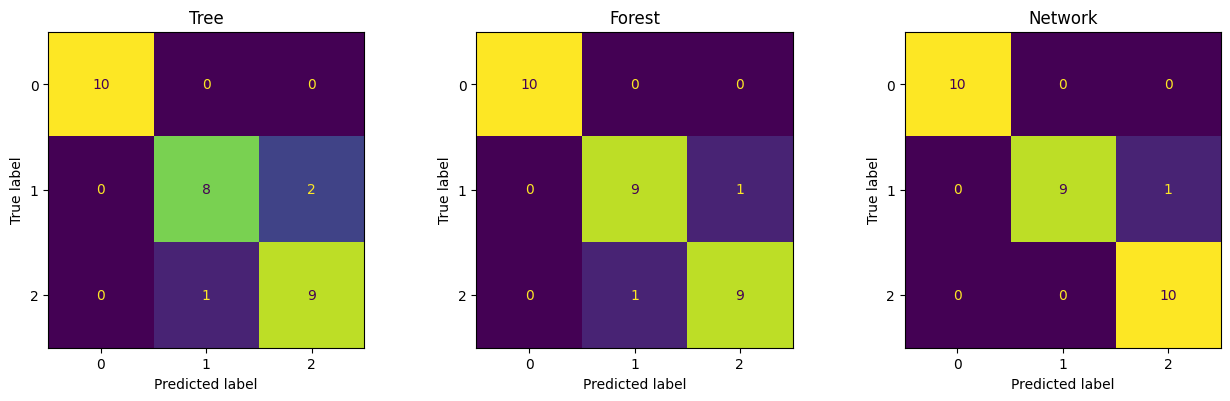

In [5]:
classification_summary = test_rows.copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y[test], model.predict(X[test]), ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Regression

Two baseline measurements predict a numerical progression score. The interface is unchanged. `predict` now returns numbers, and RMSE expresses error in score units. The neural-network pipeline scales inputs and targets using fitting statistics.

In [6]:
data = load_diabetes(scaled=False)
X, y = data.data[:, [2, 3]], data.target
feature_names = ["BMI", "average blood pressure"]
classification = False

pool, test = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED,
                             stratify=y if classification else None)
fit, val = train_test_split(pool, test_size=.25, random_state=SEED,
                           stratify=y[pool] if classification else None)
print("Fitting / validation / test", len(fit), len(val), len(test))


models = {
    "Tree": DecisionTreeRegressor(max_depth=2, min_samples_leaf=10, random_state=SEED),
    "Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=SEED, n_jobs=2),
    "Network": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16,),
                     activation="tanh", solver="lbfgs", alpha=1., max_iter=5000, random_state=SEED)),
        transformer=StandardScaler())}
for model in models.values():
    model.fit(X[fit], y[fit])

Fitting / validation / test 264 89 89


In [7]:
validation_rows = []
for name, model in models.items():
    pred = model.predict(X[val])
    value = (balanced_accuracy_score(y[val], pred) if classification
             else root_mean_squared_error(y[val], pred))
    validation_rows.append({"model": name, "validation score": value})
display(pd.DataFrame(validation_rows))

,model,validation score
0,Tree,63.866636
1,Forest,62.882528
2,Network,60.227498


Freeze settings before opening the test scores. The baseline predicts the fitting mean. A lower RMSE means smaller squared prediction errors.

In [8]:
baseline = DummyClassifier(strategy="most_frequent") if classification else DummyRegressor(strategy="mean")
baseline.fit(X[fit], y[fit])
test_rows = []
for name, model in {"Baseline": baseline, **models}.items():
    pred = model.predict(X[test])
    value = (balanced_accuracy_score(y[test], pred) if classification
             else root_mean_squared_error(y[test], pred))
    test_rows.append({"model": name, "test score": float(value)})
test_scores = pd.DataFrame(test_rows)
display(test_scores)

,model,test score
0,Baseline,79.183729
1,Tree,69.009527
2,Forest,72.233343
3,Network,67.459724


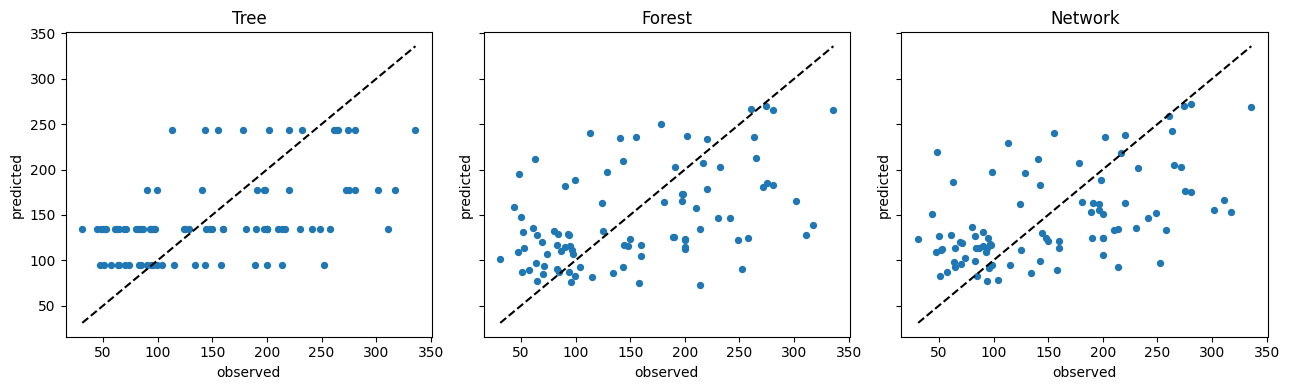

In [9]:
with open("results/simple_model_comparison.json", "w") as stream:
    json.dump({"classification": classification_summary, "regression": test_rows}, stream, indent=2)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(y[test], model.predict(X[test]), s=18)
    ax.plot([y[test].min(), y[test].max()], [y[test].min(), y[test].max()], "k--")
    ax.set(title=name, xlabel="observed", ylabel="predicted")
plt.tight_layout()
plt.show()

## Practice

Compare the classification and regression model dictionaries. Identify the changes in estimator classes, target treatment and score. Explain why a similar score can come from different predictions. Use one confusion matrix or scatter plot to support your answer.

The estimators, loss and output type change with the task. The workflow remains fit, validate, freeze, test and inspect. A table of scores summarizes performance while plots reveal which observations receive poor predictions.